
CÂU 1 - Independent t-test: charges theo smoker
Hút thuốc : n=274, mean=32050.23, sd=11541.55
Không hút : n=1063, mean=8440.66, sd=5992.97
Kiểm tra giả định:
  Shapiro-Wilk [smoker=yes]: W=0.9396, p=3.625e-09, skew=0.13
  Shapiro-Wilk [smoker=no]: W=0.8729, p=1.504e-28, skew=1.54
  Levene: stat=332.47, p=1.67e-66  -> phương sai khác nhau, dùng Welch
Welch t-test (một phía): t=32.742, df=311.9, p=3.131e-103
Hiệu trung bình = 23609.57, KTC 95% = (22190.79, 25028.35), Cohen's d = 2.57
Người hút thuốc trả gấp 3.8 lần
[Đối chiếu] Mann-Whitney U: p=2.874e-130
[Đối chiếu] Welch t-test trên log(charges): p=3.392e-234
=> Bác bỏ H0

CÂU 2 - Chi-square test of independence: sex x smoker
Bảng tần số quan sát:
 smoker   no  yes
sex             
female  547  115
male    516  159

Tỷ lệ (%) hút thuốc theo giới tính:
 smoker     no    yes
sex                 
female  82.63  17.37
male    76.44  23.56

Tần số kỳ vọng:
 smoker     no    yes
sex                 
female  526.3  135.7
male    536.7  138.3

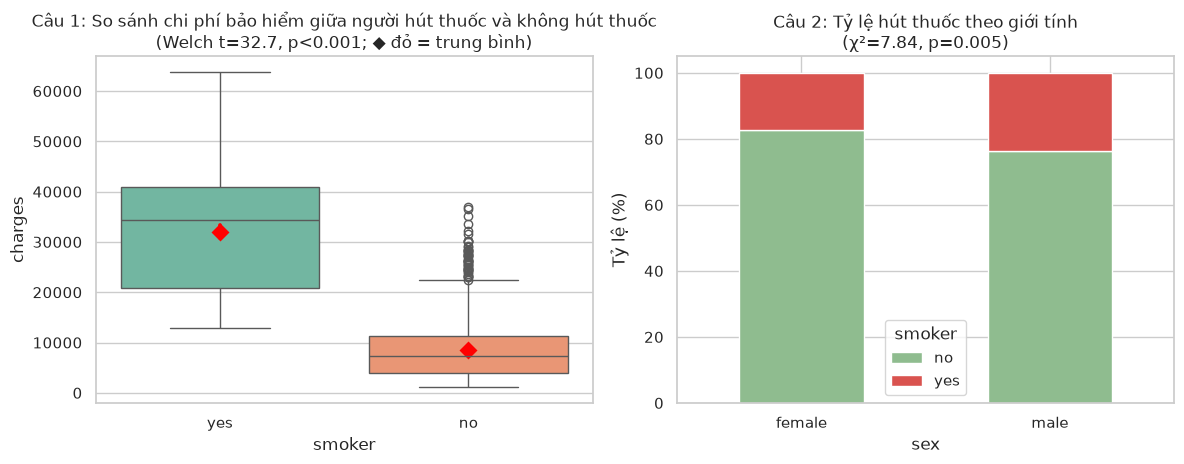

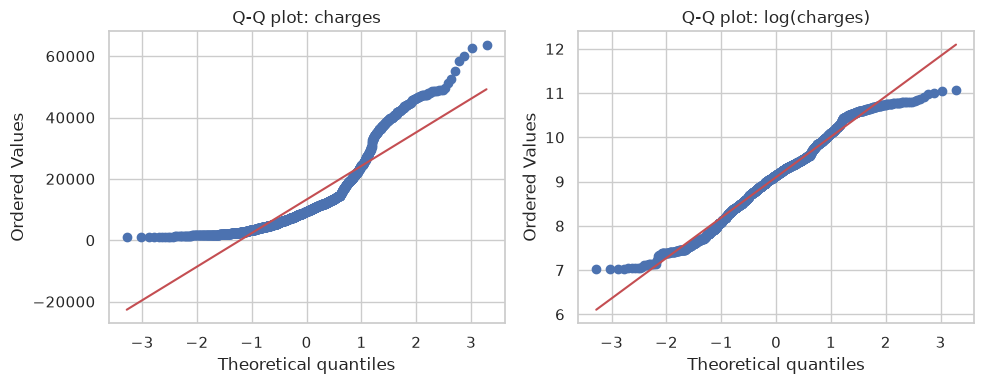

In [6]:

"""
MỤC 3 - KIỂM ĐỊNH GIẢ THUYẾT 
Câu 1: t-test     - Người hút thuốc có chi phí bảo hiểm (charges) cao hơn không?
Câu 2: Chi-square - Giới tính (sex) có liên quan đến tình trạng hút thuốc (smoker) không?
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ALPHA = 0.05
df = pd.read_csv("../shared/insurance.csv").drop_duplicates()   

def header(t):
    print("\n" + "=" * 70 + f"\n{t}\n" + "=" * 70)


# CÂU 1 (t-test)
header("CÂU 1 - Independent t-test: charges theo smoker")
yes = df.loc[df.smoker == "yes", "charges"]
no = df.loc[df.smoker == "no", "charges"]
print(f"Hút thuốc : n={len(yes)}, mean={yes.mean():.2f}, sd={yes.std():.2f}")
print(f"Không hút : n={len(no)}, mean={no.mean():.2f}, sd={no.std():.2f}")

# Kiểm tra giả định
print("Kiểm tra giả định:")
for name, g in [("smoker=yes", yes), ("smoker=no", no)]:
    w, p_s = stats.shapiro(g)
    print(f"  Shapiro-Wilk [{name}]: W={w:.4f}, p={p_s:.4g}, skew={stats.skew(g):.2f}")
lev = stats.levene(yes, no)
print(f"  Levene: stat={lev.statistic:.2f}, p={lev.pvalue:.4g}  -> phương sai khác nhau, dùng Welch")

# Welch t-test một phía (H1: hút thuốc > không hút)
t, p = stats.ttest_ind(yes, no, equal_var=False, alternative="greater")
diff = yes.mean() - no.mean()
se = np.sqrt(yes.var() / len(yes) + no.var() / len(no))
dfw = se**4 / ((yes.var() / len(yes))**2 / (len(yes) - 1)
               + (no.var() / len(no))**2 / (len(no) - 1))
ci = (diff - stats.t.ppf(0.975, dfw) * se, diff + stats.t.ppf(0.975, dfw) * se)
d = diff / np.sqrt((yes.var() + no.var()) / 2)            # Cohen's d
print(f"Welch t-test (một phía): t={t:.3f}, df={dfw:.1f}, p={p:.4g}")
print(f"Hiệu trung bình = {diff:.2f}, KTC 95% = ({ci[0]:.2f}, {ci[1]:.2f}), Cohen's d = {d:.2f}")
print(f"Người hút thuốc trả gấp {yes.mean() / no.mean():.1f} lần")

# Đối chiếu vì charges lệch phải
u, pu = stats.mannwhitneyu(yes, no, alternative="greater")
tl, pl = stats.ttest_ind(np.log(yes), np.log(no), equal_var=False, alternative="greater")
print(f"[Đối chiếu] Mann-Whitney U: p={pu:.4g}")
print(f"[Đối chiếu] Welch t-test trên log(charges): p={pl:.4g}")
print("=> Bác bỏ H0" if p < ALPHA else "=> Không đủ bằng chứng bác bỏ H0")

# CÂU 2 (Chi-square)
header("CÂU 2 - Chi-square test of independence: sex x smoker")
ct = pd.crosstab(df.sex, df.smoker)
print("Bảng tần số quan sát:\n", ct)
print("\nTỷ lệ (%) hút thuốc theo giới tính:\n",
      (pd.crosstab(df.sex, df.smoker, normalize="index") * 100).round(2))
chi2, p2, dof, expected = stats.chi2_contingency(ct, correction=False)
print("\nTần số kỳ vọng:\n", pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(1))
print(f"Giả định: tần số kỳ vọng nhỏ nhất = {expected.min():.1f} (>= 5: thỏa)")
chi2c, p2c, _, _ = stats.chi2_contingency(ct, correction=True)   # hiệu chỉnh Yates cho bảng 2x2
V = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"Chi2={chi2:.3f}, dof={dof}, p={p2:.4f}  |  Yates: chi2={chi2c:.3f}, p={p2c:.4f}")
print(f"Cramér's V = {V:.3f}  (<0.1: liên hệ rất yếu)")
print("=> Bác bỏ H0" if p2 < ALPHA else "=> Không đủ bằng chứng bác bỏ H0")

# TRỰC QUAN HÓA
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))

sns.boxplot(data=df, x="smoker", y="charges", hue="smoker", palette="Set2", legend=False, ax=ax[0])
sns.pointplot(data=df, x="smoker", y="charges", color="red", linestyle="none", markers="D", ax=ax[0])
ax[0].set_title(f"Câu 1: So sánh chi phí bảo hiểm giữa người hút thuốc và không hút thuốc\n(Welch t={t:.1f}, p<0.001; ◆ đỏ = trung bình)")

(pd.crosstab(df.sex, df.smoker, normalize="index") * 100).plot(
    kind="bar", stacked=True, color=["#8fbc8f", "#d9534f"], ax=ax[1], rot=0)
ax[1].set_ylabel("Tỷ lệ (%)")
ax[1].set_title(f"Câu 2: Tỷ lệ hút thuốc theo giới tính\n(χ²={chi2:.2f}, p={p2:.3f})")
plt.tight_layout()
plt.savefig("muc3_kiem_dinh.png", dpi=150)

# Q-Q plot kiểm tra giả định chuẩn của charges (câu 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
stats.probplot(df["charges"], plot=ax[0]); ax[0].set_title("Q-Q plot: charges")
stats.probplot(np.log(df["charges"]), plot=ax[1]); ax[1].set_title("Q-Q plot: log(charges)")
plt.tight_layout()
plt.savefig("muc3_qqplot.png", dpi=150)